In [290]:
from math import exp
from rocketpy import Fluid, LiquidMotor, CylindricalTank, MassFlowRateBasedTank, Environment, Rocket, Flight
import numpy as np
import datetime

In [291]:
isp, g0 = 220, 9.81
burn_time = 20.0
m_total = 10.25                              # kg, sum of propellant masses in both tanks
impulse_target = 0.98 * m_total * isp * g0   # N*s, 98% of propellant burned, 2% left in tankas

F_boost, F_sustain = 3500, 650               # N, levels to sustain
t_switch, width = 3.0, 0.6                   # s, centre and width of the transition (sharp/mild thrust)
t_ramp = 0.15                                # s, thrust build-up at ignition for natural liftoff sim

def _raw(t):
    ramp = 1 - np.exp(-t / t_ramp)
    step = 0.5 * (1 - np.tanh((t - t_switch) / width))
    return ramp * (F_sustain + (F_boost - F_sustain) * step)

_tt = np.linspace(0, burn_time, 4001)
_scale = impulse_target / np.trapezoid(_raw(_tt), _tt)

def thrust_curve(t):
    return _scale * _raw(t)

def flow(m0, m_total=m_total):
    # mass flow share of one tank, proportional to thrust (constant Isp)
    return lambda t: (m0 / m_total) * thrust_curve(t) / (isp * g0)

Setting up the tanks

In [292]:
# Define fluids
oxidizer_liq = Fluid(name="N2O_l", density=1220)
oxidizer_gas = Fluid(name="N2O_g", density=1.977)
fuel_liq = Fluid(name="ethanol_l", density=789)
fuel_gas = Fluid(name="ethanol_g", density=1.59)

# Define tanks geometry
tanks_shape = CylindricalTank(radius = 0.07, height = 0.5, spherical_caps = True)

# Define tanks
oxidizer_tank = MassFlowRateBasedTank(
    name="oxidizer tank",
    geometry=tanks_shape,
    flux_time=burn_time,
    initial_liquid_mass=6.1,
    initial_gas_mass=0.002,
    liquid_mass_flow_rate_in=0,
    liquid_mass_flow_rate_out=flow(6.1),
    gas_mass_flow_rate_in=0,
    gas_mass_flow_rate_out=0,
    liquid=oxidizer_liq,
    gas=oxidizer_gas,
)

fuel_tank = MassFlowRateBasedTank(
    name="fuel tank",
    geometry=tanks_shape,
    flux_time=burn_time,
    initial_liquid_mass=4.15,
    initial_gas_mass=0.002,
    liquid_mass_flow_rate_in=0,
    liquid_mass_flow_rate_out=flow(4.15),
    gas_mass_flow_rate_in=0,
    gas_mass_flow_rate_out=flow(0.002),
    liquid=fuel_liq,
    gas=fuel_gas,
)

C:\Users\PC\AppData\Local\Temp\ipykernel_33456\3957336104.py:8: DeprecationWarning: The 'radius' argument in CylindricalTank is deprecated in v1.13.0 and will be removed in v2.0.0. Use 'radius_function' instead.
  tanks_shape = CylindricalTank(radius = 0.07, height = 0.5, spherical_caps = True)
Adding spherical caps to the tank will not modify the total height of the tank (0.5000 m). Its cylindrical portion height will be reduced to 0.36 m.


Setting up the motor

In [293]:
liquid = LiquidMotor(
    thrust_source=thrust_curve,
    dry_mass=3.5,
    dry_inertia=(0.58, 0.58, 0.017),
    nozzle_radius=0.07,
    center_of_dry_mass_position=0.75,
    nozzle_position=0,
    burn_time=burn_time,
    coordinate_system_orientation="nozzle_to_combustion_chamber",
)
liquid.add_tank(tank=oxidizer_tank, position=0.55)
liquid.add_tank(tank=fuel_tank, position=1.15)

Nozzle Details
Nozzle Radius: 0.07 m

Motor Details
Total Burning Time: 20.0 s
Total Propellant Mass: 10.254 kg
Structural Mass Ratio: 0.254
Average Propellant Exhaust Velocity: 2139.914 m/s
Average Thrust: 1069.013 N
Maximum Thrust: 3599.976594795032 N at 1.2244897959183674 s after ignition.
Total Impulse: 21380.255 Ns



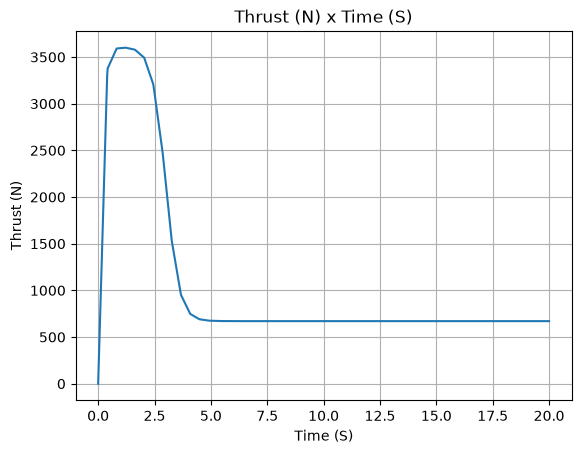

In [294]:
liquid.info()

Setting up the environment

In [295]:
env = Environment(latitude=39.4103, longitude=-8.2989, elevation=150)
env.set_atmospheric_model(type="standard_atmosphere")


Gravity Details

Acceleration of gravity at surface level:    9.8007 m/s²
Acceleration of gravity at  78.918 km (ASL): 9.5621 m/s²


Launch Site Details

Launch Date: 2026-10-29 12:00:00 UTC
Launch Site Latitude: 39.41030°
Launch Site Longitude: -8.29890°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 43693.78 W    4375726.73 N
Launch Site UTM zone: 30S
Launch Site Surface Elevation: 140.6 m


Atmospheric Model Details

Atmospheric Model Type: Forecast
Forecast Maximum Height: 78.918 km
Forecast Time Period: from 2026-10-21 03:00:00 to 2026-11-13 06:00:00 utc
Forecast Hour Interval: 3 hrs
Forecast Latitude Range: From 90.0° to -90.0°
Forecast Longitude Range: From 0.0° to 359.75°

Surface Atmospheric Conditions

Surface Wind Speed: 2.11 m/s
Surface Wind Direction: 82.77°
Surface Wind Heading: 262.77°
Surface Pressure: 1000.00 hPa
Surface Temperature: 289.82 K
Surface Air Density: 1.202 kg/m³
Surface Speed of Sound: 341.28 m/s


Earth Model Details

Earth Radius at Launch sit

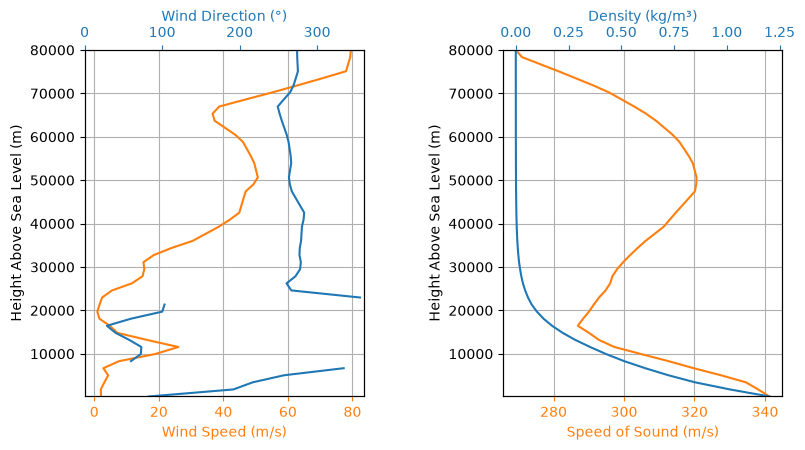

In [ ]:
env.set_date((2026, 10, 29, 12))   # rok, miesiąc, dzień, godzina (UTC)

env.set_atmospheric_model(type="Forecast", file="GFS")

env.info()

Setting up the rocket

In [297]:
power_off_cd = [(0, 0.45), (0.6, 0.45), (0.9, 0.55), (1.1, 0.80), (1.5, 0.70), (2.0, 0.58), (3.0, 0.50)]
power_on_cd = [(mach, 0.9 * cd) for mach, cd in power_off_cd]

# Payload: stack of 3 concatted CanSats (EuRoC form factor, 66 mm x 345 mm)
m_payload = 1.0                       # kg, minimum according to Euroc
r_payload, L_payload = 0.033, 0.345   # m
z_payload = 1.5                       # m, payload centre in the rocket frame (bay above the fuel tank)

# Structure without payload and motor (avionics, recovery, airframe)
m_structure = 15.0                    # kg
z_structure = 0.97                    # m
r_body, L_body = 0.1, 2.2             # m, used for the structure inertia (uniform cylinder)

# Combine structure and payload (centre of mass, then parallel-axis theorem for inertia)
rocket_mass = m_structure + m_payload
z_com = (m_structure * z_structure + m_payload * z_payload) / rocket_mass

I_structure_t = m_structure * (3 * r_body**2 + L_body**2) / 12
I_structure_a = 0.12 * m_structure / rocket_mass
I_payload_t = m_payload * (3 * r_payload**2 + L_payload**2) / 12
I_payload_a = m_payload * r_payload**2 / 2

I_t = (I_structure_t + m_structure * (z_structure - z_com) ** 2
       + I_payload_t + m_payload * (z_payload - z_com) ** 2)
I_a = I_structure_a + I_payload_a

rocket = Rocket(
    radius=0.1,
    mass=rocket_mass,
    inertia=(I_t, I_t, I_a),
    power_off_drag=power_off_cd,
    power_on_drag=power_on_cd,
    center_of_mass_without_motor=z_com,
    coordinate_system_orientation="tail_to_nose",
)

In [298]:
rocket.add_motor(liquid, position=-0.1)

In [299]:
rail_buttons = rocket.set_rail_buttons(
    upper_button_position=1.55,
    lower_button_position=0.55,
    angular_position=45,
)

nose_cone = rocket.add_nose(
    length=0.35, kind="von karman", position=2.2
)

fin_set = rocket.add_trapezoidal_fins(
    n=4,
    root_chord=0.2,
    tip_chord=0.08,
    span=0.24,
    position=0.2,
)

tail = rocket.add_tail(
    top_radius=0.1, bottom_radius=0.07, length=0.060, position=-0.05
)

In [300]:
drogue = rocket.add_parachute(
    name="drogue",
    cd_s=0.4,
    trigger="apogee",  # ejection at apogee
    sampling_rate=105,
    lag=1.0,
    noise=(0, 8.3, 0.5),
)

main = rocket.add_parachute(
    name="main",
    cd_s=4.5,
    trigger=400,       # ejection altitude in meters AGL (EuRoC requires <= 450 m)
    sampling_rate=105,
    lag=1.0,
    noise=(0, 8.3, 0.5),
)

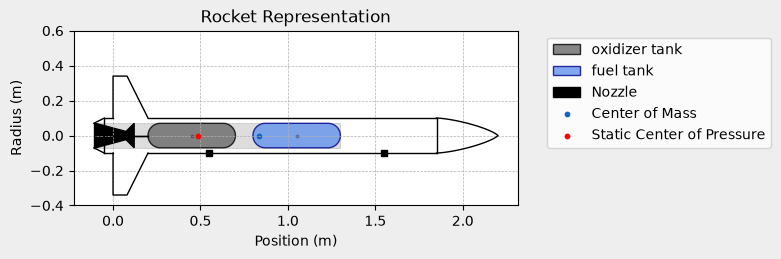

In [301]:
rocket.draw()

Setting up the flight

In [302]:
test_flight = Flight(
    rocket=rocket, environment=env, rail_length=12, inclination=85.5, heading=133
)

In [303]:
# test_flight.prints.initial_conditions()

In [304]:
test_flight.prints.surface_wind_conditions()


Surface Wind Conditions

Frontal Surface Wind Speed: -1.35 m/s
Lateral Surface Wind Speed: -1.62 m/s


In [305]:
# test_flight.prints.launch_rail_conditions()

In [306]:
test_flight.prints.out_of_rail_conditions()


Rail Departure State

Rail Departure Time: 0.652 s
Rail Departure Velocity: 45.793 m/s
Rail Departure Stability Margin: 1.767 c
Rail Departure Angle of Attack: 2.625°
Rail Departure Thrust-Weight Ratio: 12.338
Rail Departure Reynolds Number: 6.145e+05


In [307]:
# test_flight.prints.burn_out_conditions()

In [308]:
test_flight.prints.apogee_conditions()


Apogee State

Apogee Time: 39.450 s
Apogee Altitude: 7434.276 m (ASL) | 7293.717 m (AGL)
Apogee Freestream Speed: 35.889 m/s
Apogee X position: 1409.318 m
Apogee Y position: -846.719 m
Apogee latitude: 39.4026824°
Apogee longitude: -8.2824938°


In [309]:
# test_flight.prints.events_registered()

In [310]:
test_flight.prints.impact_conditions()


Impact Conditions

Time of impact: 287.547 s
X impact: 1708.653 m
Y impact: -772.970 m
Altitude impact: 140.559 m (ASL) | 0.000 m (AGL) 
Latitude: 39.4033452°
Longitude: -8.2790089°
Vertical velocity at impact: -8.406 m/s
Number of parachutes triggered until impact: 2


## Visualization: flight and stability

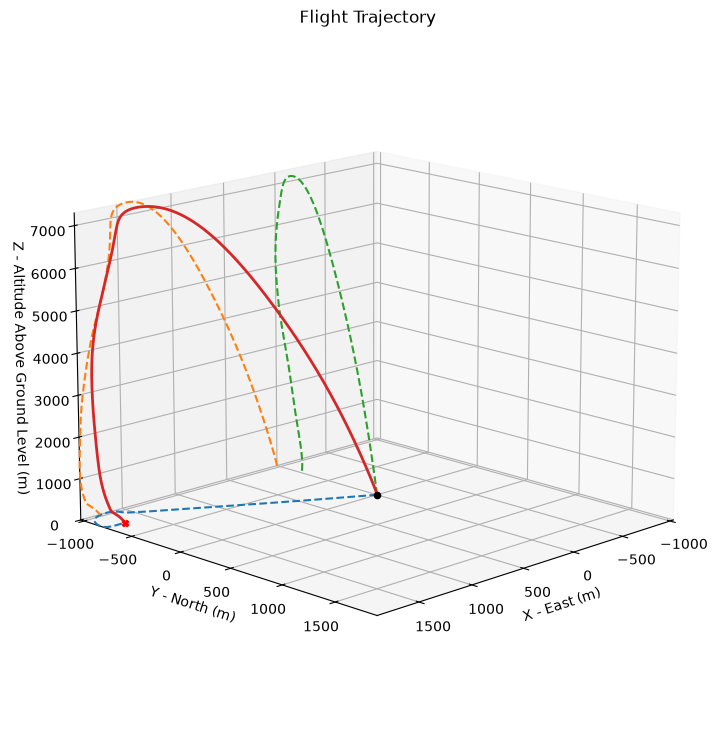

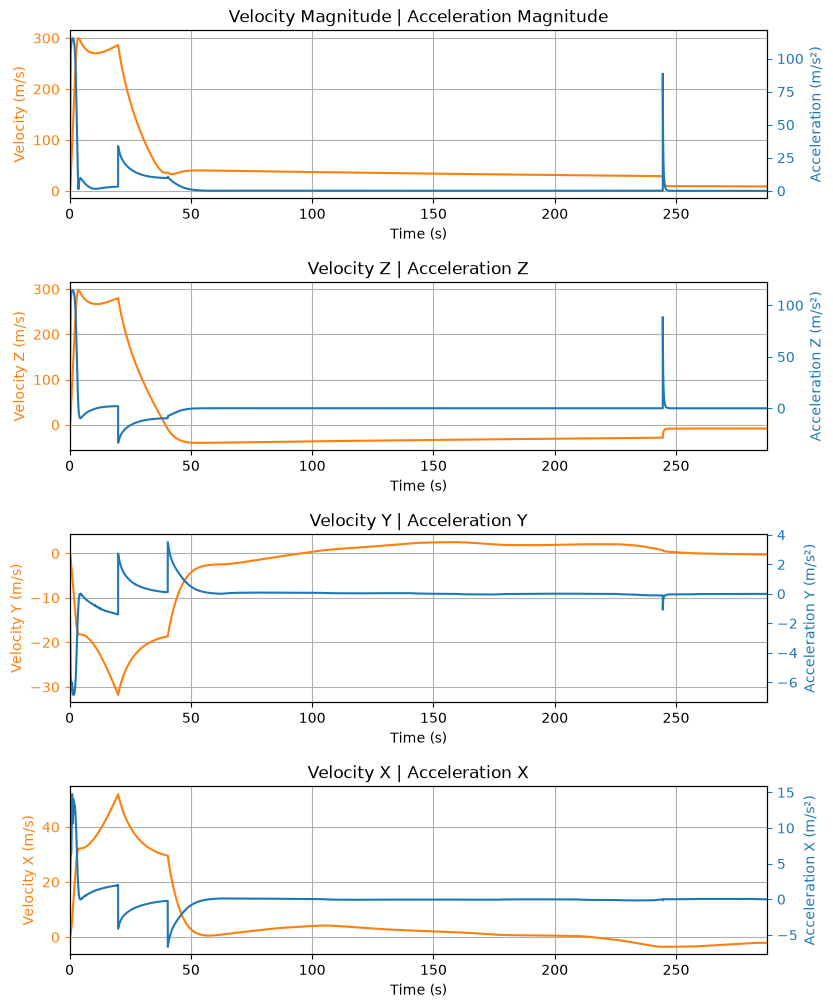

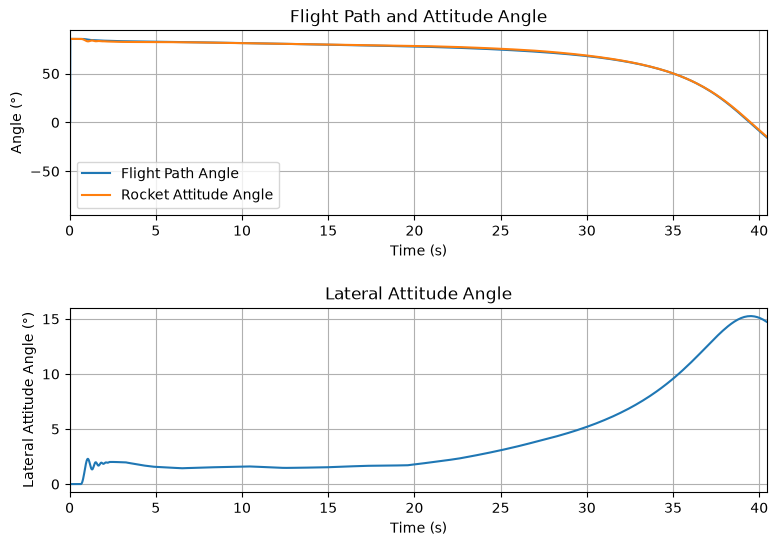

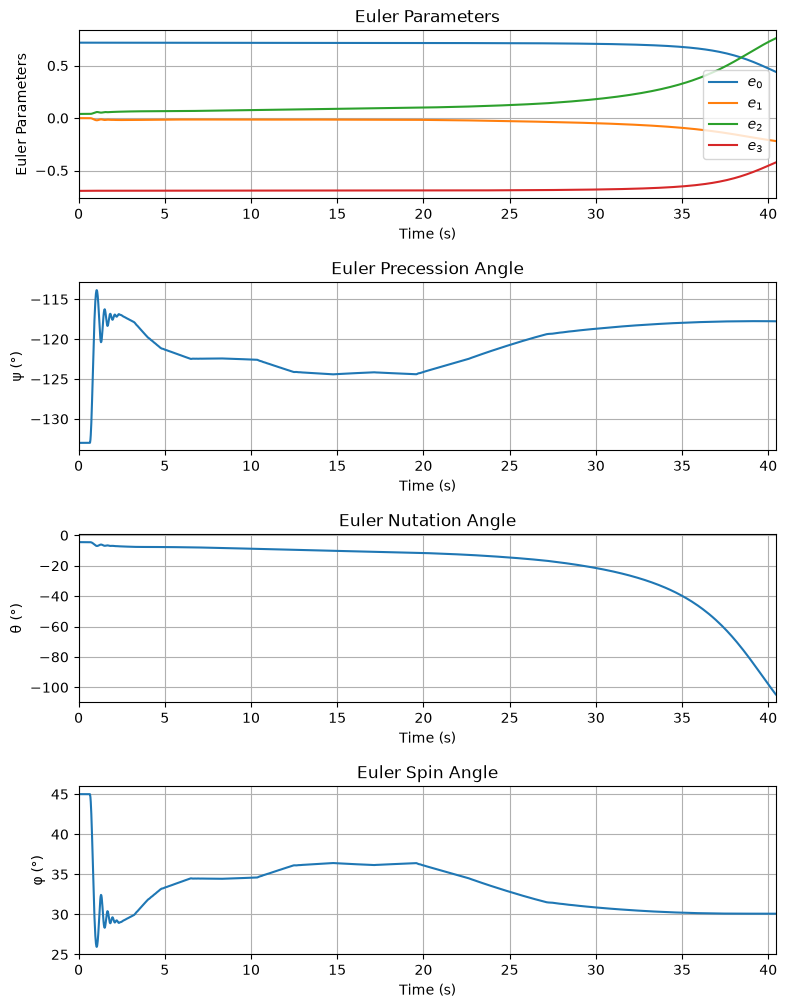

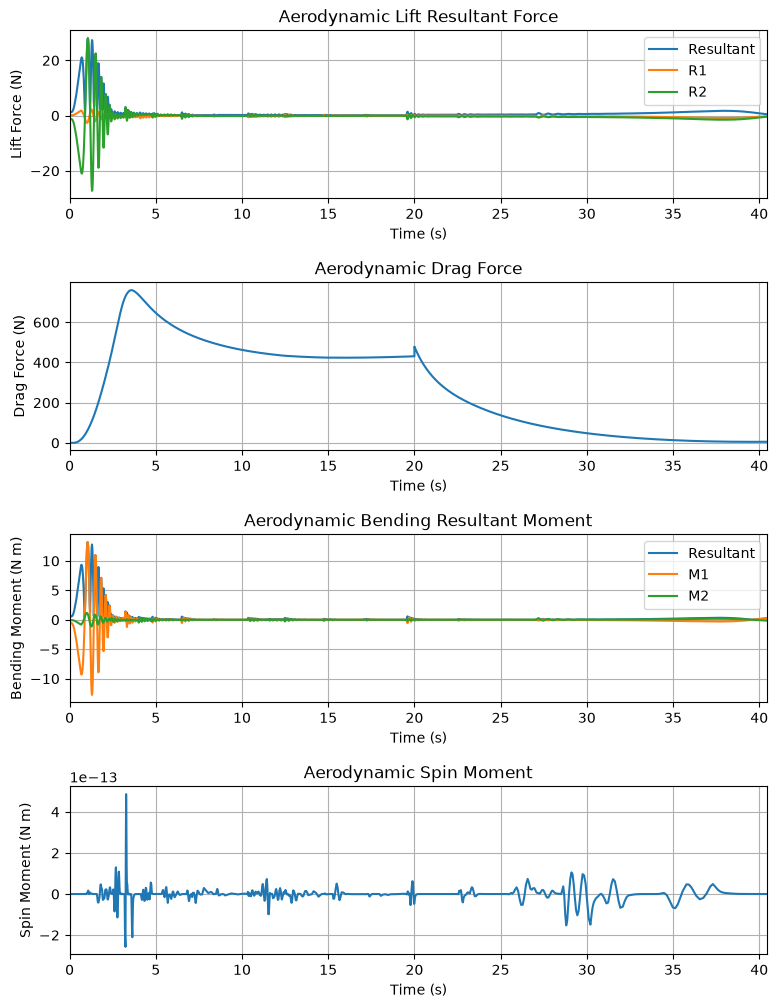

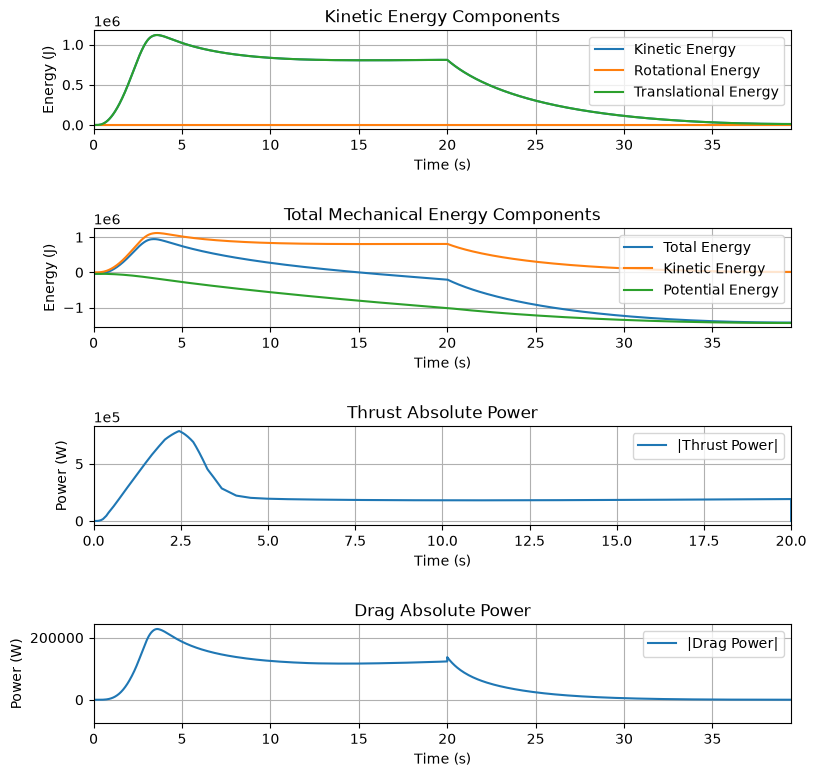

In [311]:
# Flight: trajectory, kinematics, forces and energy
test_flight.plots.trajectory_3d()
test_flight.plots.linear_kinematics_data()
test_flight.plots.flight_path_angle_data()
test_flight.plots.attitude_data()
test_flight.plots.aerodynamic_forces()
test_flight.plots.energy_data()

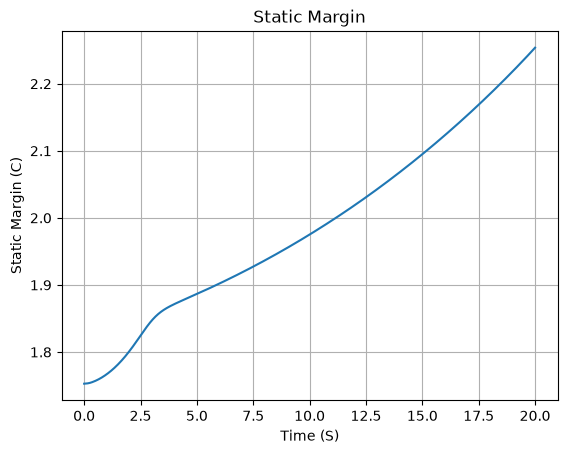

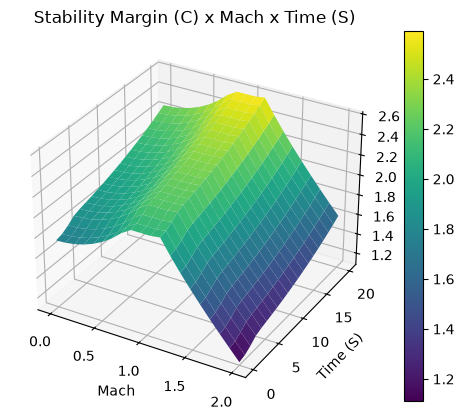

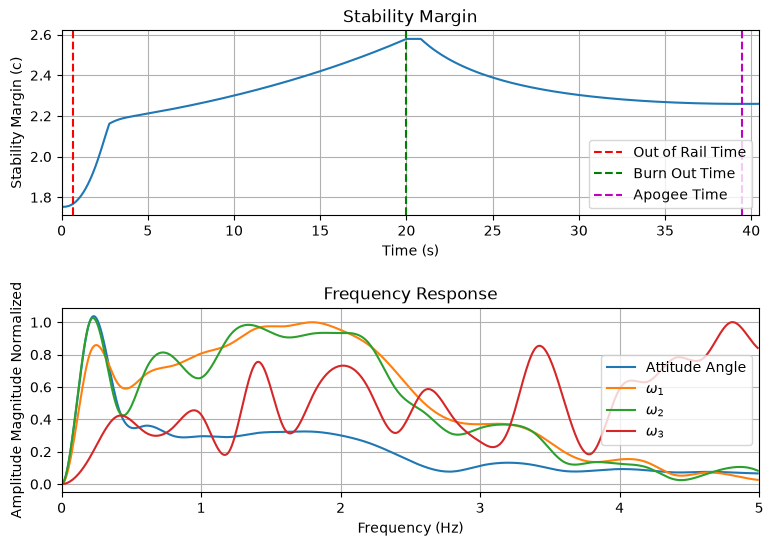

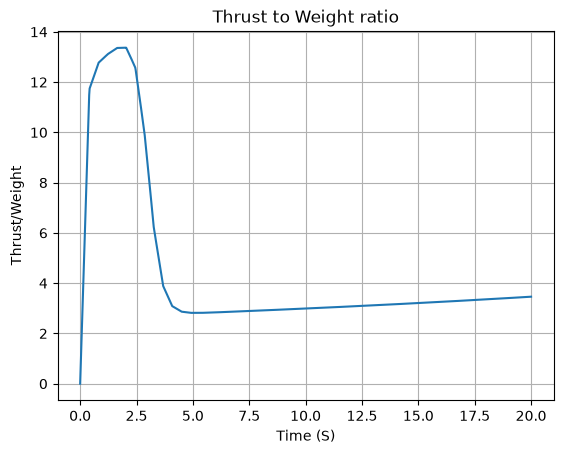

In [312]:
# Stability: margin over time, margin vs Mach, thrust-to-weight, drag curves
rocket.plots.static_margin()
rocket.plots.stability_margin()
test_flight.plots.stability_and_control_data()
rocket.plots.thrust_to_weight()
# rocket.plots.drag_curves()

## Experiment: hull mass vs flight performance


In [313]:
import pandas as pd


def build_experiment_rocket(m_structure, z_structure=0.97):
    """Build a fresh rocket with the given structure (hull) mass.

    Independent of the objects created above: it only reads env, example_liquid
    and the drag tables, and rebuilds mass, centre of mass and inertia itself.
    """
    m_pl, r_pl, L_pl, z_pl = 1.0, 0.033, 0.345, 1.5      # payload (same as above)
    r_b, L_b = 0.1, 2.2                                   # body radius / length

    m = m_structure + m_pl
    z_cm = (m_structure * z_structure + m_pl * z_pl) / m
    I_t = (m_structure * (3 * r_b**2 + L_b**2) / 12 + m_structure * (z_structure - z_cm) ** 2
           + m_pl * (3 * r_pl**2 + L_pl**2) / 12 + m_pl * (z_pl - z_cm) ** 2)
    I_a = 0.12 * m_structure / m + m_pl * r_pl**2 / 2

    r = Rocket(
        radius=r_b,
        mass=m,
        inertia=(I_t, I_t, I_a),
        power_off_drag=power_off_cd,
        power_on_drag=power_on_cd,
        center_of_mass_without_motor=z_cm,
        coordinate_system_orientation="tail_to_nose",
    )
    r.add_motor(liquid, position=-0.1)
    r.set_rail_buttons(upper_button_position=1.55, lower_button_position=0.55, angular_position=45)
    r.add_nose(length=0.35, kind="von karman", position=2.2)
    r.add_trapezoidal_fins(n=4, root_chord=0.2, tip_chord=0.08, span=0.24, position=0.2)
    r.add_tail(top_radius=0.1, bottom_radius=0.07, length=0.060, position=-0.05)
    r.add_parachute(name="drogue", cd_s=0.4, trigger="apogee", sampling_rate=105, lag=1.0, noise=(0, 8.3, 0.5))
    r.add_parachute(name="main", cd_s=4.5, trigger=400, sampling_rate=105, lag=1.0, noise=(0, 8.3, 0.5))
    return r


exp_masses = [11, 13, 15, 17, 19]   # kg, structure (hull) mass without payload and motor
exp_flights = {}
exp_rows = []
for exp_m in exp_masses:
    exp_rocket = build_experiment_rocket(exp_m)
    exp_flight = Flight(
        rocket=exp_rocket, environment=env, rail_length=12, inclination=84.5, heading=133,
    )
    exp_flights[exp_m] = exp_flight
    t_rail = exp_flight.out_of_rail_time
    ts = np.linspace(t_rail, exp_flight.apogee_time, 300)
    exp_rows.append({
        "hull mass [kg]": exp_m,
        "liftoff mass [kg]": exp_rocket.total_mass(0),
        "apogee AGL [m]": exp_flight.apogee - env.elevation,
        "rail exit speed [m/s]": exp_flight.out_of_rail_velocity,
        "max speed [m/s]": exp_flight.max_speed,
        "max Mach": exp_flight.max_mach_number,
        "static margin at rail [cal]": exp_flight.stability_margin(t_rail),
        "min margin after rail [cal]": min(exp_flight.stability_margin(t) for t in ts),
        "impact speed [m/s]": abs(exp_flight.impact_velocity),
        "drift [m]": np.hypot(exp_flight.x_impact, exp_flight.y_impact),
    })

exp_results = pd.DataFrame(exp_rows).set_index("hull mass [kg]")
exp_results.round(2)

,liftoff mass [kg],apogee AGL [m],rail exit speed [m/s],max speed [m/s],max Mach,static margin at rail [cal],min margin after rail [cal],impact speed [m/s],drift [m]
hull mass [kg],,,,,,,,,
11,25.75,7427.79,49.19,333.41,0.98,1.66,1.66,7.49,2005.08
13,27.75,7352.15,47.39,316.64,0.93,1.72,1.72,7.96,2083.01
15,29.75,7236.83,45.80,299.92,0.88,1.77,1.77,8.41,2152.48
17,31.75,7079.67,44.33,283.57,0.85,1.81,1.81,8.83,2210.66
19,33.75,6882.46,43.03,273.65,0.83,1.85,1.85,9.23,2255.14


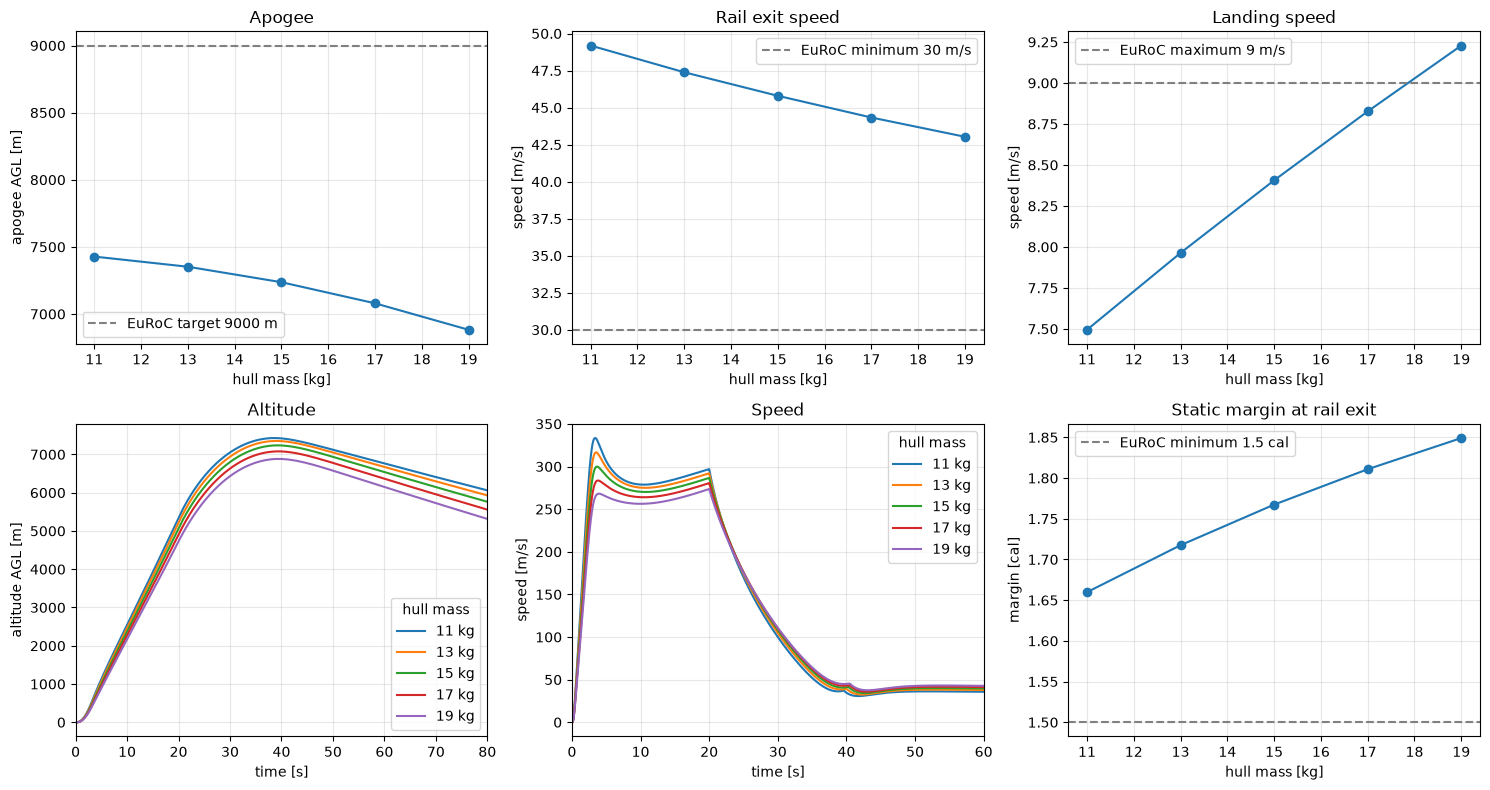

In [314]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.ravel()
hull = exp_results.index

ax[0].plot(hull, exp_results["apogee AGL [m]"], "o-")
ax[0].axhline(9000, ls="--", c="gray", label="EuRoC target 9000 m")
ax[0].set(title="Apogee", xlabel="hull mass [kg]", ylabel="apogee AGL [m]")
ax[0].legend()

ax[1].plot(hull, exp_results["rail exit speed [m/s]"], "o-")
ax[1].axhline(30, ls="--", c="gray", label="EuRoC minimum 30 m/s")
ax[1].set(title="Rail exit speed", xlabel="hull mass [kg]", ylabel="speed [m/s]")
ax[1].legend()

ax[2].plot(hull, exp_results["impact speed [m/s]"], "o-")
ax[2].axhline(9, ls="--", c="gray", label="EuRoC maximum 9 m/s")
ax[2].set(title="Landing speed", xlabel="hull mass [kg]", ylabel="speed [m/s]")
ax[2].legend()

for m, f in exp_flights.items():
    ax[3].plot(f.z.source[:, 0], f.z.source[:, 1] - env.elevation, label=f"{m} kg")
    ax[4].plot(f.speed.source[:, 0], f.speed.source[:, 1], label=f"{m} kg")
ax[3].set(title="Altitude", xlabel="time [s]", ylabel="altitude AGL [m]", xlim=(0, 80))
ax[4].set(title="Speed", xlabel="time [s]", ylabel="speed [m/s]", xlim=(0, 60))
ax[3].legend(title="hull mass")
ax[4].legend(title="hull mass")

ax[5].plot(hull, exp_results["static margin at rail [cal]"], "o-")
ax[5].axhline(1.5, ls="--", c="gray", label="EuRoC minimum 1.5 cal")
ax[5].set(title="Static margin at rail exit", xlabel="hull mass [kg]", ylabel="margin [cal]")
ax[5].legend()

for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()